  Preparing metadata (setup.py) ... done
              precision    recall  f1-score   support

normal/noise       1.00      1.00      1.00       600
         arc       1.00      1.00      1.00       600

    accuracy                           1.00      1200
   macro avg       1.00      1.00      1.00      1200
weighted avg       1.00      1.00      1.00      1200

[[600   0]
 [  0 600]]


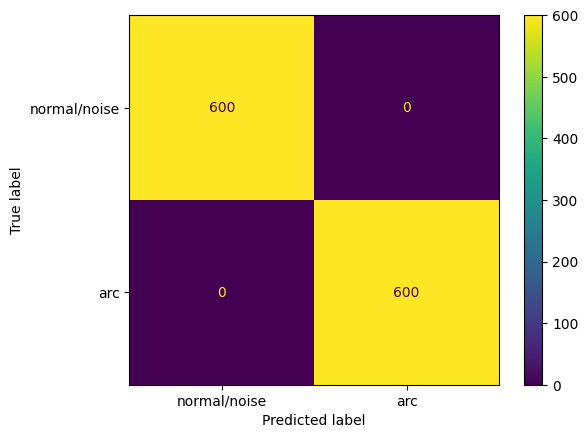

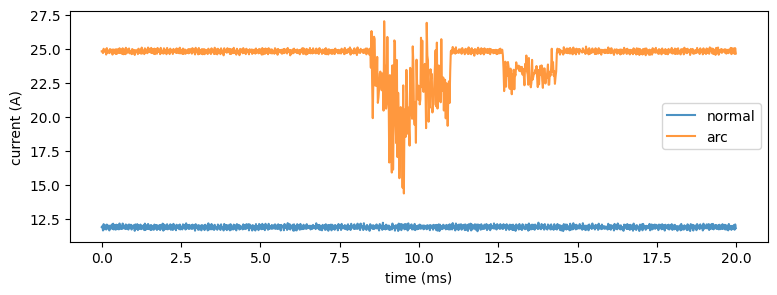

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
!pip install micromlgen scikit-learn matplotlib -q
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from micromlgen import port
from google.colab import files

rng = np.random.default_rng(42)
FS, N = 50_000, 1000          # 50 kHz sampling, 20 ms window
t = np.arange(N) / FS

def normal():
    return rng.uniform(5, 30) + 0.2*np.sin(2*np.pi*20_000*t) + rng.normal(0, 0.05, N)

def disturbance():             # harmless: load step + isolated EMI spikes
    x = normal()
    x[rng.integers(100, 900):] += rng.uniform(-3, 3)
    for _ in range(rng.integers(0, 3)):
        x[rng.integers(0, N)] += rng.uniform(1, 4)
    return x

def arc():                     # broadband bursts + current dip
    x = normal()
    for _ in range(rng.integers(2, 6)):
        s = rng.integers(0, N-120); l = rng.integers(40, 120)
        x[s:s+l] += rng.normal(0, rng.uniform(0.6, 2.0), l) - rng.uniform(0.5, 3)
    return x

def feats(x):
    d = np.diff(x)
    return [x.mean(), x.std(), np.abs(d).max(), (d**2).mean()]

rows = []
for _ in range(1500): rows.append(feats(normal())      + [0])
for _ in range(1500): rows.append(feats(disturbance()) + [0])
for _ in range(3000): rows.append(feats(arc())         + [1])
df = pd.DataFrame(rows, columns=["mean","std","max_di","di_energy","label"])
df.to_csv("synthetic_arc_dataset.csv", index=False)

X, y = df.drop(columns="label"), df["label"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=1)
clf = DecisionTreeClassifier(max_depth=4).fit(Xtr, ytr)
pred = clf.predict(Xte)

print(classification_report(yte, pred, target_names=["normal/noise","arc"]))
cm = confusion_matrix(yte, pred)
print(cm)
ConfusionMatrixDisplay(cm, display_labels=["normal/noise","arc"]).plot()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

# sample waveform plot for the report
plt.figure(figsize=(9,3))
plt.plot(t*1000, normal(), label="normal", alpha=.8)
plt.plot(t*1000, arc(), label="arc", alpha=.8)
plt.xlabel("time (ms)"); plt.ylabel("current (A)"); plt.legend()
plt.savefig("waveforms.png", dpi=150, bbox_inches="tight")
plt.show()

open("arc_model.h", "w").write(port(clf))
for f in ["synthetic_arc_dataset.csv", "arc_model.h", "confusion_matrix.png", "waveforms.png"]:
    files.download(f)